# Практическое задание №2

## Задание
Используйте файл с информацией о ноутбуках `laptops_na.csv`.

[Источник данных](https://www.kaggle.com/datasets/bhavikjikadara/brand-laptops-dataset)


В нём содержаться следующие переменные:

- `brand`: Название бренда ноутбука.
- `Model`: Конкретная модель или серия ноутбука.
- `Price`: Цена ноутбука в индийских рупиях.
- `Rating`: Рейтинг, присвоенный ноутбуку на основе его характеристик.
- `processor_brand`: Марка процессора, используемого в ноутбуке.
- `processor_tier`: Уровень производительности или категория процессора.
- `num_cores`: Количество вычислительных ядер в процессоре.
- `num_threads`: Количество потоков, поддерживаемых процессором.
- `ram_memory`: Объем оперативной памяти, используемый в ноутбуке.
- `primary_storage_type`: Тип основного хранилища (например, HDD, SSD).
- `primary_storage -apacity`: Емкость основного хранилища ноутбука.
- `secondary_storage_type`: Тип вторичного хранилища, если оно доступно.
- `secondary_storage_capacity`: Емкость вторичного хранилища ноутбука.
- `gpu_brand`: Марка графического процессора (GPU).
- `gpu_type`: Тип графического процессора.
- `is_touch_screen`: Указывает, оснащен ли ноутбук функцией сенсорного экрана.
- `display_size`: Размер дисплея ноутбука в дюймах.
- `resolution_width`: Разрешение по ширине дисплея.
- `resolution_height`: Разрешение дисплея по высоте.
- `OS`: Установленная на ноутбуке операционная система.
- `year_of_warranty`: Срок гарантии, предоставляемой на ноутбук, обычно в годах.

Обратите внимание, что все пункты задания должны сопровождаться _выполненным_ фрагментом кода!

In [2]:
import pandas as pd
import seaborn as sns
import numpy as np
from scipy.stats import norm, shapiro, chi2_contingency
import pingouin as pg
import matplotlib.pyplot as plt

df = pd.read_csv("laptops_na.csv")

### Задание 1. Проверка отличия распределения от «нормального»

Проанализируйте распределение значений 5-ти любых метрических переменных. Проведите тест для проверки того отличается ли распределение значений переменных от нормального распределения. Сформулируйте гипотезы и выводы по результатам анализа. Постройте гистограммы распределения с наложенной кривой нормального распределения. 

H0: Распределения анализируемых переменных статистически значимо не отличается от нормального распределения.

H1: Распределения анализируемых переменных статистически значимо отличается от нормального распределения.


p-value < 0.05 (стандартный уровень значимости - 5%)

Price осталось значений: 942 из 991
W = 0.7374442998537247 p-value = 4.3432229060016456e-36 

Rating осталось значений: 936 из 991
W = 0.9909340982878817 p-value = 1.609500768482758e-05 

primary_storage_capacity осталось значений: 928 из 991
W = 0.6548590583189893 p-value = 1.2351238093822565e-39 

num_threads осталось значений: 953 из 991
W = 0.9107111489078454 p-value = 3.284676189655623e-23 

display_size осталось значений: 943 из 991
W = 0.783026168963374 p-value = 1.3983108988778764e-33 



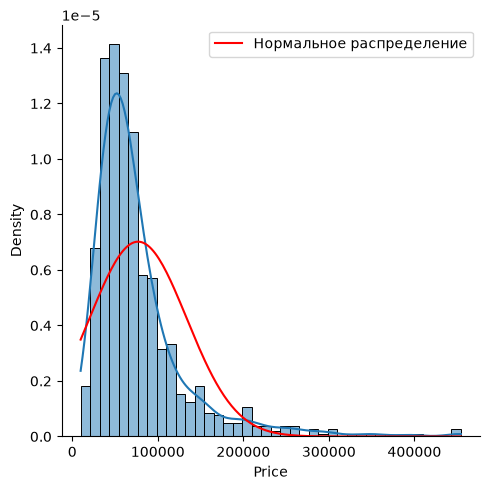

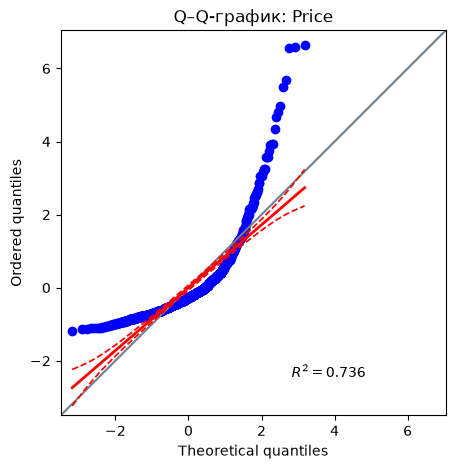

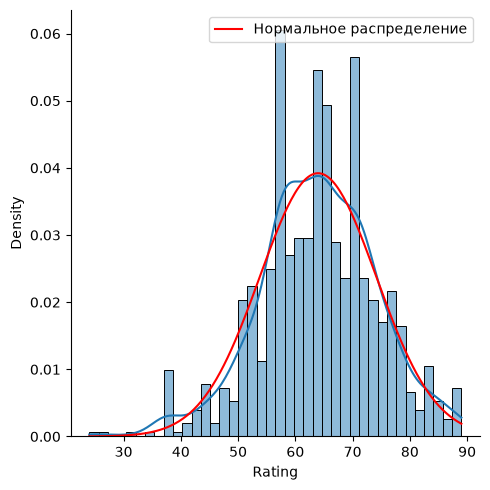

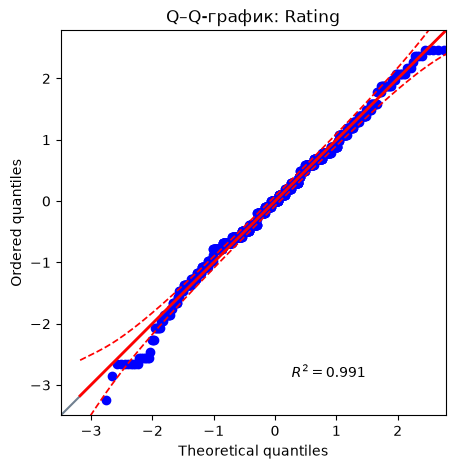

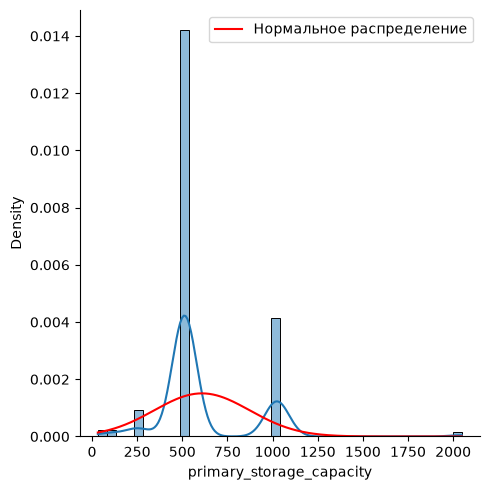

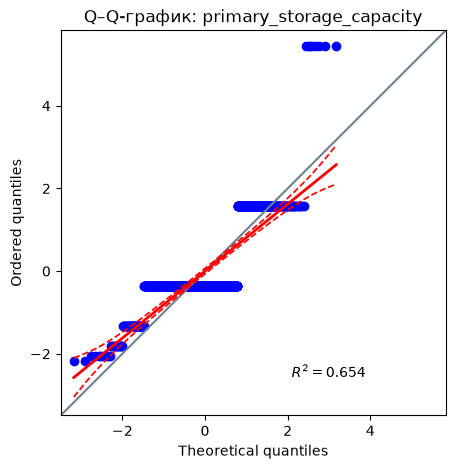

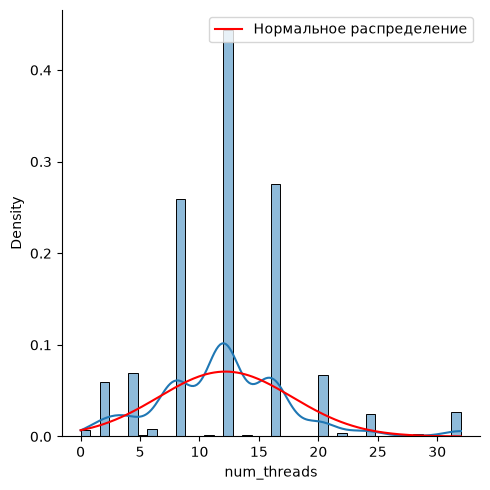

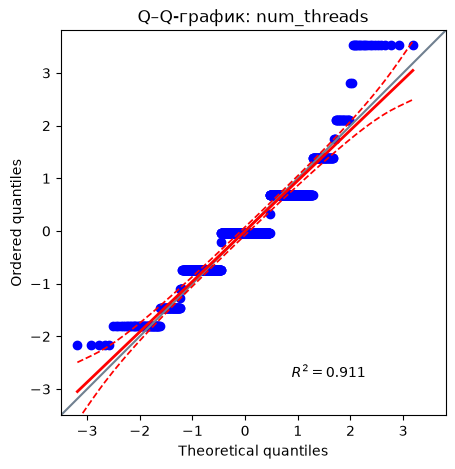

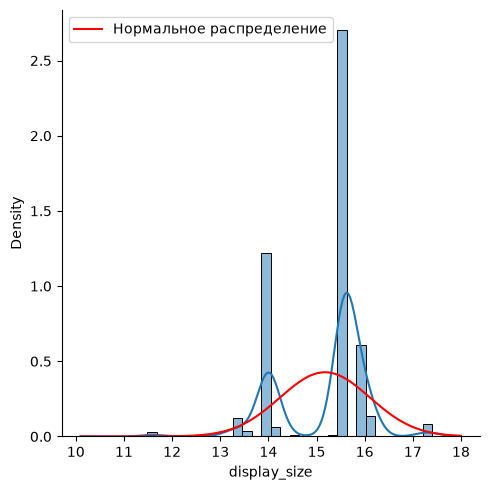

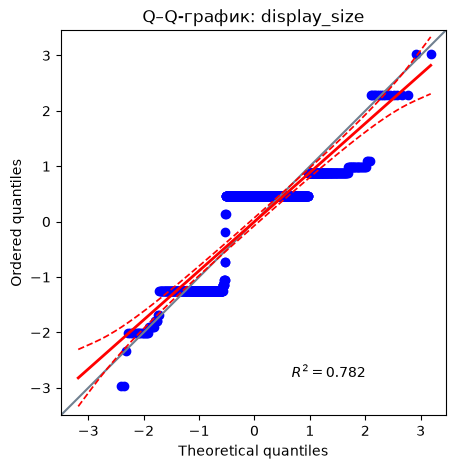

In [45]:
features = ["Price", "Rating", "primary_storage_capacity","num_threads", "display_size"]

for feature in features:
    back = df[feature]
    x = df[feature].dropna()
    print(feature, "осталось значений:", len(x), "из", len(back))
    g = sns.displot(data=df, x = x, bins = 40, stat="density", kde = True, height = 5)
     
    grid = np.linspace(x.min(), x.max(), 200)
    density = norm.pdf(grid, loc=x.mean(), scale=x.std())
    sns.lineplot(x=grid, y=density, ax=g.ax, color="red",
                 label="Нормальное распределение")
    
    statistic, p_value = shapiro(x)
    print("W =", statistic, "p-value =", p_value, '\n')
    
    fig, ax = plt.subplots(figsize=(5, 5))
    pg.qqplot(x, dist='norm', ax=ax)
    ax.set_title(f"Q–Q-график: {feature}")

**Вывод**<br>
Для всех пяти переменных тест Шапиро - Уилка p-value < 0.05 => по нашей гипотезе и порогу в 0.05 H0 отвергается, что согласуется с гистограммами (самое ближнее было у фичи Rating, там p-value 1.61e-05 и на графике видно, что они похожи). <br>
Также добавил Q-Q графики, по которым еще более наглядно видно, насколько распределения переменных отличаются от нормальных
| Переменная | Наблюдения по гистограмме |
| --- | --- |
| Price | Распределение имеет правостороннюю асимметрию, большинство ноутбуков находится в области сравнительно небольших цен, а дорогие формируют большой правый хвост |
| Rating | Общая форма похожа на нормальную кривую, но заметны 2 отдельных пика |
| primary_storage_capacity | Значения сосредоточены в основном около 512 и 1024 ГБ |
| num_threads | Распределение дискретное, с выраженными пиками около 8, 12 и 16 потоков |
| display_size | Значения находятся около стандартных размеров экранов, особенно 14 и 15.6 дюйма |

### Задание 2. Тест Хи-квадрат

Проведите тест Хи-квадрат не менее, чем с двумя парами переменных, для которых он применим. Можно использовать как исходные переменные, так и перекодировать их. Постройте для выбранных пар переменных таблицы сопряженности и прокомментируйте их. Сформулируйте гипотезы. Интерпретируйте результаты анализа. Обоснуйте свои выводы. Визуализируйте наблюдаемые тенденции на подходящих графиках.

H0: бренд процессора и анализируемый признак независимы (в 1 случае признак это тип gpu, во втором бренд ноутбука)

H1: между брендом процессора и анализируемым признаком существует связь (в 1 случае признак это тип gpu, во втором бренд ноутбука)

p-value < 0.05 (стандартный уровень значимости - 5%)

gpu_type,dedicated,integrated
processor_brand,,
amd,101,134
intel,217,417


chi2 =  5.2885325615941685    p-value = 0.021466301052513407


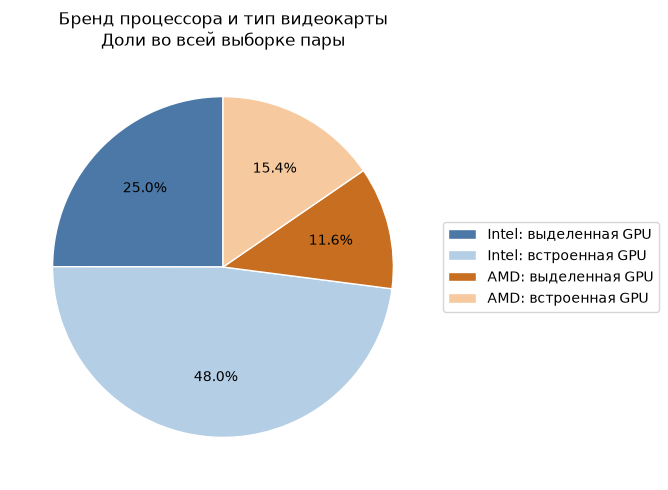

brand,acer,asus,dell,hp,lenovo,msi,other_brands
processor_brand,,,,,,,
amd,16,54,12,66,67,14,6
intel,66,130,77,117,115,67,60


chi2 =  42.13153674756681    p-value = 1.73201719638976e-07


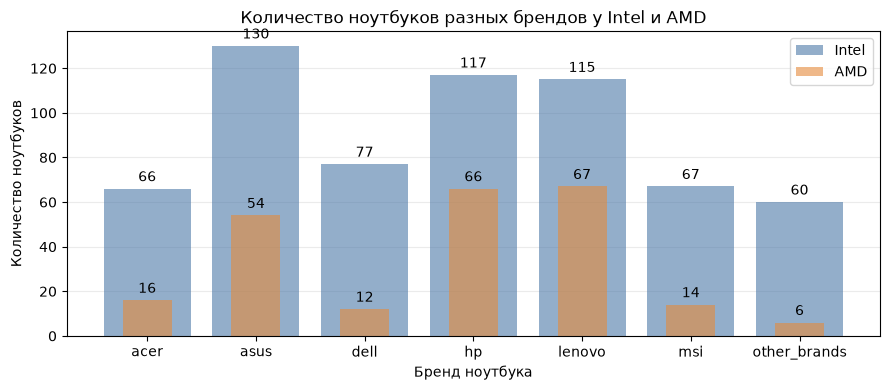

In [ ]:

features = [["processor_brand", "gpu_type"],["processor_brand", "brand"]]
for i in features:
    if(i[1] == "gpu_type"):
        filtered = df[
            df["processor_brand"].isin(["amd", "intel"])
            & df["gpu_type"].isin(["dedicated", "integrated"])
        ]
        ct = pd.crosstab(filtered["processor_brand"], filtered["gpu_type"])   
    else:
        filtered = df[
            df["processor_brand"].isin(["amd", "intel"])
        ].copy()

        common_brands = ["asus", "lenovo", "hp", "dell", "acer", "msi"]

        rare_brands = (
            filtered["brand"].notna()
            & ~filtered["brand"].isin(common_brands)
        )

        filtered.loc[rare_brands, "brand"] = "other_brands"

        ct = pd.crosstab(
            filtered["processor_brand"],
            filtered["brand"]
        )
    display(ct)
    print('chi2 = ', chi2_contingency(ct)[0], '   p-value =', chi2_contingency(ct)[1])

    if i[1] == "gpu_type":
        pie_table = ct.reindex(index=["intel", "amd"], columns=["dedicated", "integrated"])
        fig, ax = plt.subplots(figsize=(9, 5))
        outer_wedges, _, _ = ax.pie(
            pie_table.to_numpy().ravel(), radius=1, startangle=90,
            colors=["#4c78a8", "#b4cee6", "#c86e21", "#f6c99f"],
            autopct="%1.1f%%", pctdistance=0.65,
            wedgeprops={"width": 1, "edgecolor": "white"}
        )
        ax.legend(
            outer_wedges,
            ["Intel: выделенная GPU", "Intel: встроенная GPU",
             "AMD: выделенная GPU", "AMD: встроенная GPU"],
            loc="center left", bbox_to_anchor=(1, 0.5)
        )
        ax.set_title("Бренд процессора и тип видеокарты")
    else:
        positions = np.arange(len(ct.columns))
        fig, ax = plt.subplots(figsize=(9, 4))
        
        intel_bars = ax.bar(positions, ct.loc["intel"], width=0.8, color="#4c78a8", alpha=0.6, label="Intel")
        amd_bars = ax.bar(positions, ct.loc["amd"], width=0.45, color="#e58a3a", alpha=0.6, label="AMD")
        
        ax.bar_label(intel_bars, padding=3)
        ax.bar_label(amd_bars, padding=3)
        
        ax.set_xticks(positions, ct.columns)
        ax.set_xlabel("Бренд ноутбука")
        ax.set_ylabel("Количество ноутбуков")
        ax.set_title("Количество ноутбуков разных брендов у Intel и AMD")
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.25)
        ax.legend()
    plt.tight_layout()
    plt.show()


**Вывод**<br>
Я использовал 2 пары фичей: бренд процессора - тип gpu и бренд процессора - бренд ноутбука. Обе пары пришлось менять, так как в некоторых ячейках были слишком маленькие ожидаемые частоты(условно в бредах ноутбука было много ноунейм ноутбуков, которые в датасете всего пару штук, поэтому условия применения обычного теста хи-квадрат не выполнялись, аналогично с первой парой - были ноутбуки apple которые работают на своем отдельном железе).<br>

Я решил это так, в 1 случае убрал все остальные случае и теперь сравниваю только долю AMD и Intel в integrated и dedicated gpu. Во втором случае я оставил только самые популярные бренды ноутбуков, остальные обьединил в other.<br>

**Бренд процессора и тип GPU**<br>
На выборке из 869 ноутбуков получено x^2 ~ 5.29 и p-value ~ 0.0215. Так как p-value < 0.05, H0 отвергается, между брендом процессора и типом видеокарты обнаружена статистически значимая связь. Среди всех ноутбуков AMD dedicated GPU встречается у 11.6%, а с Intel 25.0%, что видно на круговой диаграме. Также видно проценты integrated GPU.

**Бренд процессора и бренд ноутбука.**<br> 
На выборке из 867 ноутбуков получено x^2 ~ 42.13 и p-value ~ 1.73 × 10^-7. Это меньше 0.05, поэтому H0 тоже отвергается, распределение брендов ноутбуков связано с брендом процессора. Например среди ноутбуков с AMD доли HP и Lenovo составляют 28.1% и 28.5%, а среди ноутбуков с Intel 18.5% и 18.2%. На столбчатом графике показаны абсолютные количества. Ноутбуков с Intel в этой таблице больше чем AMD: 632 против 235, поэтому более высокие столбцы Intel сами по себе не означают более высокую долю соответствующего бренда.

### Задание 3. Парная корреляция

Проведите корреляционный анализ переменных (нужно рассмотреть не менее трёх разных пар переменных). Обоснуйте выбор рассчитываемых коэффициентов корреляции. Сформулируйте гипотезы. Визуализируйте наблюдаемые тенденции на подходящих графиках. Интерпретируйте результаты анализа (статистическая значимость, сила и направление взаимосвязи). Заполните таблицу (не менее 3 записей). 	 	 	 	 

| Анализируемые пары переменных | Выбранный коэффициент корреляции (обоснование выбора) | Гипотезы | Сила взаимосвязи | Направление взаимосвязи | Статистическая значимость взаимосвязи |
| --- | --- | --- | --- | --- | --- |
| --- | --- | --- | --- | --- | --- |
| --- | --- | --- | --- | --- | --- |
| --- | --- | --- | --- | --- | --- |


In [47]:
# здесь можно написать код

### Задание 4. Частная корреляция
Посчитайте парный коэффициент корреляции между выбранной парой переменных. Посчитайте частный коэффициент корреляции между этими переменными, исключив влияние любой третьей переменной. Сделайте выводы. Визуализируйте наблюдаемые тенденции на подходящих графиках.

In [48]:
# здесь можно написать код

**Комментарии к заданию и принципам его оценивания:**

- Все пункты задания должны сопровождаться _выполненным_ фрагментом кода.
- Если Вы получили результаты в виде статистических показателей, таблиц или графиков, при этом никак их не прокомментировали и не сформулировали содержательные выводы на их основе, то работа оценивается в 0 баллов, в этом случае анализ данных не проведён.
- Если Вы полностью выполнили это задание, то получаете за него 8 баллов (отлично). Для получения более высокой оценки нужно выйти за рамки предложенного задания. В случае с текущим заданием это может быть дополнительное самостоятельное изучение методов оценки взаимосвязей между переменными и их применение для анализа данных, или развернутое и глубокое исследование имеющихся данных на основе использования пройденных на занятиях инструментов.
- В этом задании четыре пункта. Каждый из них весит 25%. 
- Задание можно выполнять индивидуально или в группе из 2 человек, критерии оценивания при этом не меняются;
- В названии загружаемого в Smart LMS файла нужно указать фамилию(ии) автора(ов) работы.
- В случае использования в работе ИИ необходимо указать где и как именно он использовался.

### Этот файл нужно сохранить как Jupyter Notebook (.ipynb) и загрузить в Smart LMS до 23:55 18 октября.